In [1]:
import pandas as pd

df = pd.read_csv("/content/books_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000, 5)


,Title,Price_GBP,Rating,Availability,Product_URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [2]:

# ==========================================
# CodeAlpha - Task 2
# Exploratory Data Analysis (EDA)
# Step 1: Data Quality & Statistical Summary
# ==========================================

import pandas as pd

print("=" * 55)
print("DATASET OVERVIEW")
print("=" * 55)

print("\nDataset Dimensions:")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nColumn Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDuplicate Product URLs:")
print(df["Product_URL"].duplicated().sum())

print("\nStatistical Summary:")
display(df[["Price_GBP", "Rating"]].describe())

print("\nRating Distribution:")
print(df["Rating"].value_counts().sort_index())

print("\nAvailability Distribution:")
print(df["Availability"].value_counts())

print("\nPrice Skewness:")
print(round(df["Price_GBP"].skew(), 3))

print("\nCorrelation Between Price and Rating:")
print(round(df["Price_GBP"].corr(df["Rating"]), 3))


DATASET OVERVIEW

Dataset Dimensions:
Rows: 1000
Columns: 5

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         1000 non-null   object 
 1   Price_GBP     1000 non-null   float64
 2   Rating        1000 non-null   int64  
 3   Availability  1000 non-null   object 
 4   Product_URL   1000 non-null   object 
dtypes: float64(1), int64(1), object(3)
memory usage: 39.2+ KB

Missing Values:
Title           0
Price_GBP       0
Rating          0
Availability    0
Product_URL     0
dtype: int64

Duplicate Records:
0

Duplicate Product URLs:
0

Statistical Summary:


,Price_GBP,Rating
count,1000.00000,1000.000000
mean,35.07035,2.923000
std,14.44669,1.434967
min,10.00000,1.000000
25%,22.10750,2.000000
50%,35.98000,3.000000
75%,47.45750,4.000000
max,59.99000,5.000000



Rating Distribution:
Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64

Availability Distribution:
Availability
In stock    1000
Name: count, dtype: int64

Price Skewness:
-0.038

Correlation Between Price and Rating:
0.028


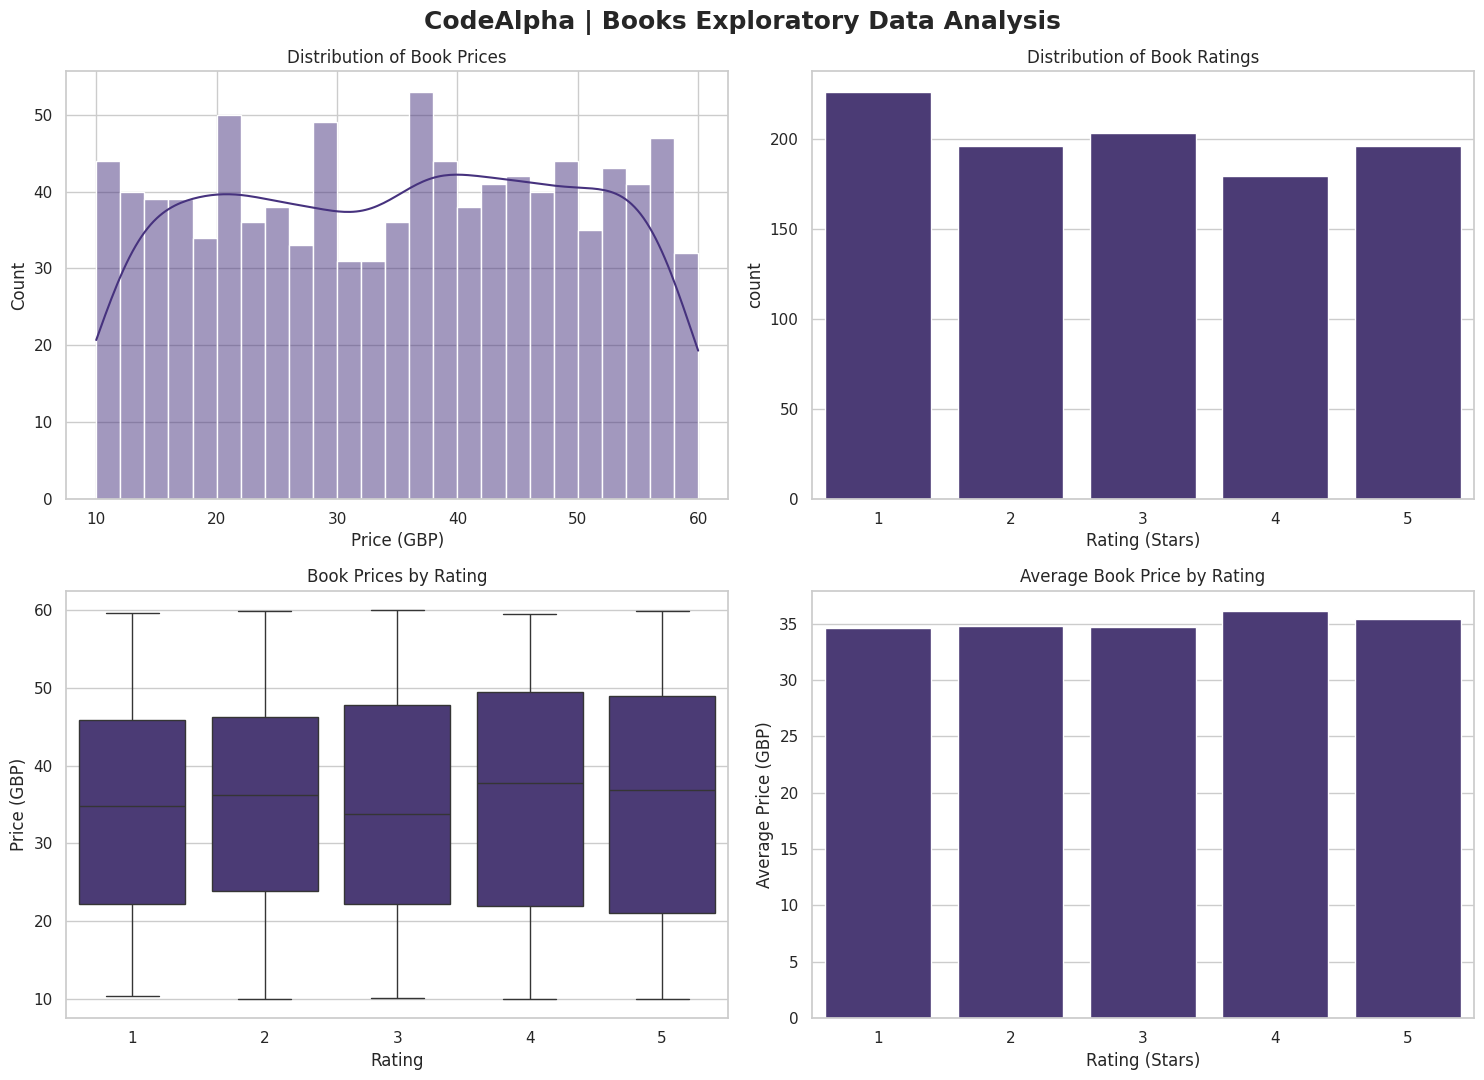

In [3]:

# CodeAlpha - Task 2: EDA Visualizations

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Price Distribution
sns.histplot(
    data=df,
    x="Price_GBP",
    bins=25,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Book Prices")
axes[0, 0].set_xlabel("Price (GBP)")

# 2. Rating Distribution
sns.countplot(
    data=df,
    x="Rating",
    order=[1, 2, 3, 4, 5],
    ax=axes[0, 1]
)
axes[0, 1].set_title("Distribution of Book Ratings")
axes[0, 1].set_xlabel("Rating (Stars)")

# 3. Price by Rating
sns.boxplot(
    data=df,
    x="Rating",
    y="Price_GBP",
    order=[1, 2, 3, 4, 5],
    ax=axes[1, 0]
)
axes[1, 0].set_title("Book Prices by Rating")
axes[1, 0].set_ylabel("Price (GBP)")

# 4. Average Price by Rating
avg_price = df.groupby("Rating")["Price_GBP"].mean()

sns.barplot(
    x=avg_price.index,
    y=avg_price.values,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Average Book Price by Rating")
axes[1, 1].set_xlabel("Rating (Stars)")
axes[1, 1].set_ylabel("Average Price (GBP)")

plt.suptitle(
    "CodeAlpha | Books Exploratory Data Analysis",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "task2_eda_visualizations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [4]:
# Statistical Analysis - CodeAlpha Task 2

skewness = df["Price_GBP"].skew()
correlation = df["Price_GBP"].corr(df["Rating"])

print("=" * 45)
print("STATISTICAL ANALYSIS RESULTS")
print("=" * 45)

print(f"Price Skewness: {skewness:.4f}")
print(f"Price-Rating Correlation: {correlation:.4f}")

STATISTICAL ANALYSIS RESULTS
Price Skewness: -0.0375
Price-Rating Correlation: 0.0282


In [5]:

# CodeAlpha Task 2 - Hypothesis Testing

from scipy.stats import pearsonr

# H0: No linear correlation between price and rating
# H1: A linear correlation exists

correlation, p_value = pearsonr(
    df["Price_GBP"],
    df["Rating"]
)

print("=" * 50)
print("HYPOTHESIS TESTING RESULTS")
print("=" * 50)

print(f"Pearson Correlation: {correlation:.4f}")
print(f"P-value: {p_value:.4f}")

alpha = 0.05

if p_value < alpha:
    print("Result: Reject the null hypothesis.")
    print("There is statistical evidence of a linear relationship.")
else:
    print("Result: Fail to reject the null hypothesis.")
    print("Insufficient evidence of a linear relationship.")

print("=" * 50)


HYPOTHESIS TESTING RESULTS
Pearson Correlation: 0.0282
P-value: 0.3736
Result: Fail to reject the null hypothesis.
Insufficient evidence of a linear relationship.


In [6]:
report = """CODEALPHA - TASK 2: EXPLORATORY DATA ANALYSIS

Dataset: Books to Scrape
Total Records: 1000
Missing Values: 0
Duplicate Records: 0

KEY FINDINGS
Average Price: GBP 35.07
Median Price: GBP 35.98
Average Rating: 2.923 / 5
Price Skewness: -0.0375
Price-Rating Correlation: 0.0282
P-value: 0.3736

HYPOTHESIS TEST
H0: No linear correlation between price and rating.
H1: A linear correlation exists.
Significance Level: 0.05

CONCLUSION
Fail to reject H0.
There is insufficient statistical evidence of a
linear relationship between book price and rating.

LIMITATION
Books to Scrape is a demonstration website.
Results should not be generalized to the real book market.
"""

with open("task2_eda_report.txt", "w", encoding="utf-8") as f:
    f.write(report)

from google.colab import files
files.download("task2_eda_report.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>